# Welcome to the RandQuantKry Tutorial
 
This is the basic introduction to the usage of **RandQuantKry** on how to set up a hamiltonian, an initial state and run a time evolution. <a href="tutorial_evolution_methods.ipynb"><b>How to call the different evolution methods</b></a>, <a href="tutorial_benchmarking.ipynb"><b>benchmarking</b></a> and <a href="tutorial_parameter_study.ipynb"><b>parameter study</b></a> tutorials can be found in the respectively named Jupyter Notebooks. Happy learning :)

## Quantum State Evolution

In quantum simulation, we study how a quantum state $|\psi(t)\rangle$ evolves over time under a given Hamiltonian operator $\hat{H}$. This dynamics is governed by the **time-dependent Schrödinger equation**:

$$i \hbar \frac{d}{dt} |\psi(t)\rangle = \hat{H} |\psi(t)\rangle$$

For a time-independent Hamiltonian $\hat{H}$, the exact solution for evolving an initial state $|\psi(0)\rangle$ to time $t$ is given by applying the unitary time-evolution operator $\hat{U}(t) = e^{-i \hat{H} t / \hbar}$ (working in natural units where $\hbar = 1$):

$$|\psi(t)\rangle = e^{-i \hat{H} t} |\psi(0)\rangle$$

<div class="alert alert-block alert-warning">
<b>NOTE:</b>  Please install the package by following the instructions in the <a href="../README.md"><b>README.md</b></a>.

</div> 

In [16]:
# imports
import numpy as np
import matplotlib.pyplot as plt
# these files can be found in src/ and are the main building blocks of this package
from randquantkry.hamiltonian import build_hamiltonian
from randquantkry.evolution import time_evolve_naive
from randquantkry.observables import print_quantum_state, plot_unitary_matrix, display_quantum_state_latex, plot_state_histogram, plot_operator_subblock, plot_hamiltonian_heatmap, plot_operator_sparsity 

# utils/ contains all helper functions that allow for example logging
from randquantkry.utils.logging_config import configure_logging

In [2]:
configure_logging(console_level='INFO')

14:36:15 | INFO     | randquantkry | logging configured (console only)


<Logger randquantkry (DEBUG)>

### Step 1: Create your first Hamiltonian

In this step, we construct an **$8$-qubit Transverse-Field Ising Model (TFIM)** Hamiltonian with nearest-neighbor interactions and randomized coupling parameters. 

Mathematically, the Hamiltonian operator $\hat{H}$ is defined as:

$$\hat{H} = \sum_{i=0}^{N-1} h_i \hat{X}_i + \sum_{i=0}^{N-2} J_{i, i+1} \hat{Z}_i \hat{Z}_{i+1}$$

Where:
* $N = 8$ is the total number of qubits.
* $\hat{X}_i$ represents a Pauli-$X$ transverse magnetic field applied to qubit $i$, with random local field strengths $h_i \in [0.5, 1.5)$.
* $\hat{Z}_i \hat{Z}_{i+1}$ represents nearest-neighbor longitudinal coupling between adjacent qubits $i$ and $i+1$, with random interaction strengths $J_{i, i+1} \in [0.3, 0.8)$.

In [3]:
n_qubits = 8
rng = np.random.default_rng(0)

terms = []
for i in range(n_qubits):
    terms.append(('X', i, float(rng.uniform(0.5, 1.5))))       # X field, every qubit
for i in range(n_qubits - 1):
    terms.append(('ZZ', i, float(rng.uniform(0.3, 0.8))))      # ZZ coupling, every neighboring pair

hamiltonian = build_hamiltonian(n_qubits, terms)
display(hamiltonian)

SparsePauliOp(['XIIIIIII', 'IXIIIIII', 'IIXIIIII', 'IIIXIIII', 'IIIIXIII', 'IIIIIXII', 'IIIIIIXI', 'IIIIIIIX', 'ZZIIIIII', 'IZZIIIII', 'IIZZIIII', 'IIIZZIII', 'IIIIZZII', 'IIIIIZZI', 'IIIIIIZZ'],
              coeffs=[1.13696169+0.j, 0.76978671+0.j, 0.54097352+0.j, 0.51652764+0.j,
 1.31327024+0.j, 1.41275558+0.j, 1.10663578+0.j, 1.22949656+0.j,
 0.5718125 +0.j, 0.76753621+0.j, 0.70792678+0.j, 0.30136925+0.j,
 0.72870214+0.j, 0.31679279+0.j, 0.66482772+0.j])

Hmmmm that is a little hard to read, let's make it a bit easier to visualize:

<Axes: title={'center': 'Hamiltonian Sparsity Pattern\n(256x256 Matrix)'}, xlabel='Basis State Index ($j$)', ylabel='Basis State Index ($i$)'>

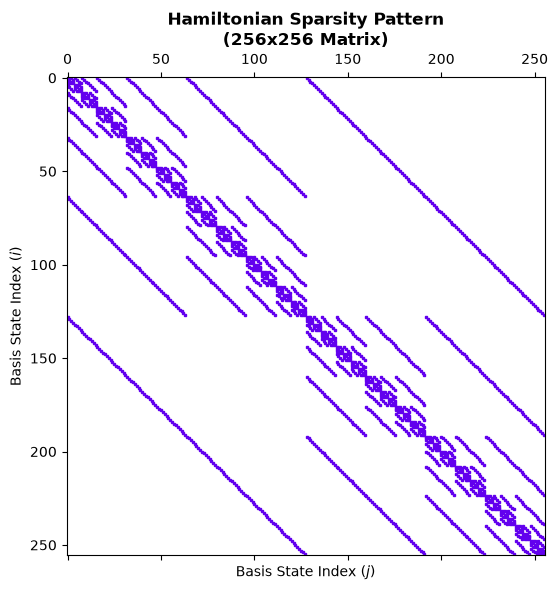

In [4]:
plot_operator_sparsity(np.asarray(hamiltonian))

Here you can see the sparsity pattern of the 256 x 256 (so $2^8$ x $2^8$) Hamiltonian matrix representation. But you might be wondering what this looks in a little bit more detail:

<Axes: title={'center': 'Hamiltonian Sub-block H (8x8)'}, xlabel='State $|j\\rangle$', ylabel='State $|i\\rangle$'>

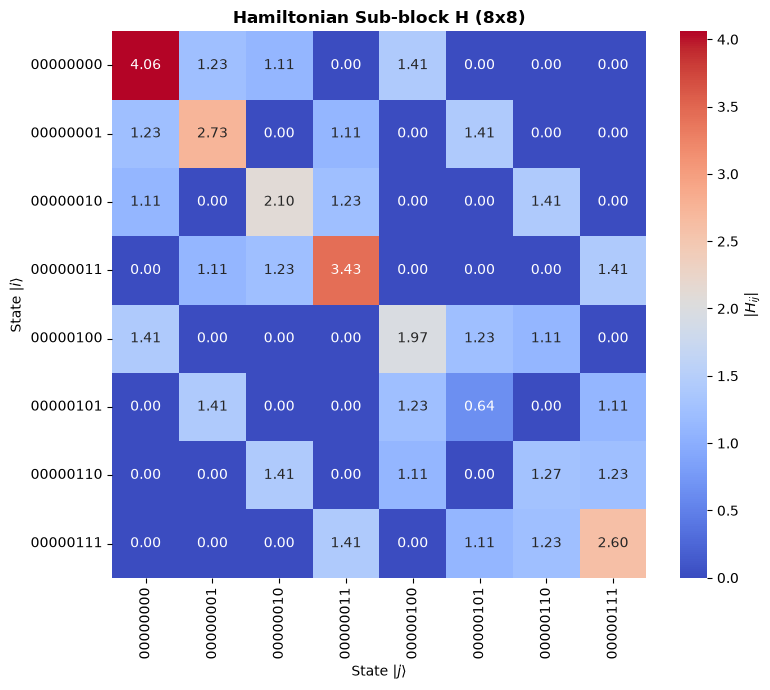

In [5]:
plot_operator_subblock(np.asarray(hamiltonian), block_size=8)

This colormap shows a smaller cut out of the first 8 x 8 states and we can tell there are quite a lot of zero states as we would expect based on the sprasity pattern above.

### Step 2: Set the Initial State

Before running time evolution, we define the initial quantum state vector $\vert{}\psi(0)\rangle$ in the computational basis. 

Mathematically, an $N$-qubit state vector lives in a Hilbert space of dimension $2^N$:

$$\vert{}\psi(0)\rangle = \vert{}0\rangle^{\otimes N} = \vert{}10\dots0\rangle = \begin{pmatrix} 1 \\ 0 \\ \vdots \\ 0 \end{pmatrix} \in \mathbb{C}^{2^N}$$

In this example, we initialize the system in the ground product state $\vert{}10\dots0\rangle$, which corresponds to setting the entry with index `128` of the state vector to `1.0`.

<div class="alert alert-block alert-warning">
<b>Important: </b>  Qiskit's Little-Endian Convention

Quantum frameworks like **Qiskit** use **little-endian** bit ordering to index qubits in computational basis states: 
$\vert{}q_{N-1} \, q_{N-2} \, \dots \, q_1 \, q_0\rangle$

 * **Qubit 0 ($q_0$)** corresponds to the **least significant bit** (rightmost position).
 * **Qubit $N-1$ ($q_{N-1}$)** corresponds to the **most significant bit** (leftmost position).

 So just keep in mind that state $\vert{}00\dots01\rangle$ corresponds to array index $1$, whereas textbook big-endian notation ($\vert{}10\dots00\rangle$) corresponds to index $2^{N-1}$.
</div> 

In [6]:
n_qubits = hamiltonian.num_qubits
initial_state = np.zeros(2**n_qubits, dtype=complex)
initial_state[128] = 1.0 #|10000000>
print(initial_state)

[0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j
 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j
 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j
 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j
 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j
 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j
 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j
 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j
 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j
 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j
 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j
 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j
 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 1.+0.j 0.+0.j
 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j
 0.+0.

This also looks quite confusing, good that we have a function to actually see the 8 qubit initial state  $\vert{}10000000\rangle$

In [7]:
print_quantum_state(initial_state, label="|ψ(0)⟩")

|ψ(0)⟩ = |10000000⟩


### Step 3: Now lets evolve this state for time t = 1.0

The time_evolve_naive function takes the hamiltonian, we just created, the intial state and the time that we want to evolve the state for and performs exact spectral decomposition (eigendecomposition) of the Hamiltonian matrix.

#### Mathematical Foundation

Instead of computing the matrix exponential $e^{-i \hat{H} t}$ directly via series expansion (which can be numerically unstable), we diagonalize the Hermitian Hamiltonian operator $\hat{H}$:

$$\hat{H} = \mathbf{V} \mathbf{\Lambda} \mathbf{V}^\dagger$$

Where:
* $\mathbf{\Lambda} = \operatorname{diag}(E_0, E_1, \dots, E_{2^N-1})$ is the diagonal matrix of real energy eigenvalues $E_k$.
* $\mathbf{V}$ is the unitary matrix whose columns are the corresponding eigenvectors $\vert{}E_k\rangle$.

Applying the function $f(\hat{H}) = e^{-i \hat{H} t}$ yields the exact unitary time-evolution operator $\hat{U}(t)$:

$$\hat{U}(t) = e^{-i \hat{H} t} = \mathbf{V} \, e^{-i \mathbf{\Lambda} t} \, \mathbf{V}^\dagger = \mathbf{V} \begin{pmatrix} e^{-i E_0 t} & & 0 \\ & \ddots & \\ 0 & & e^{-i E_{2^N-1} t} \end{pmatrix} \mathbf{V}^\dagger$$

The evolved state is then obtained via matrix-vector multiplication:

$$\vert{}\psi(t)\rangle = \hat{U}(t) \vert{}\psi(0)\rangle$$

<div class="alert alert-block alert-danger">
<b>Computational Scalability Warning:</b> 

Exact diagonalization scales as $\mathcal{O}(2^{3N})$ in computation time and requires storing a dense $2^N \times 2^N$ matrix ($\mathcal{O}(2^{2N})$ memory). Because of this exponential bottleneck, naive evolution is **strictly restricted to small systems** ($N \le 12$ qubits for 16GB RAM).

</div>

In [8]:
unitary, evolved_state_naive = time_evolve_naive(hamiltonian, initial_state, time = 1.0)

14:36:16 | INFO     | randquantkry.evolution | time_evolve_naive: starting | {'context': {'n_qubits': 8, 'matrix_dim': 256, 'time': 1.0}}
14:36:19 | INFO     | randquantkry.evolution | time_evolve_naive: complete | {'context': {'evolved_state_norm': 1.0}}


In [9]:
print_quantum_state(evolved_state_naive,label="|ψ(1)⟩")

|ψ(1)⟩ = (+0.0593-0.0897j) |00000000⟩ + (+0.0321-0.1044j) |00000001⟩ + (+0.0290-0.0352j) |00000010⟩ + (-0.1555-0.0911j) |00000011⟩ + (+0.0145-0.0505j) |00000100⟩ + (+0.0008-0.0357j) |00000101⟩ + (+0.0174-0.0304j) |00000110⟩ + (-0.1224-0.0077j) |00000111⟩ + (+0.0079-0.0402j) |00001000⟩ + (-0.0192-0.0693j) |00001001⟩ + (-0.0132+0.0024j) |00001010⟩ + (-0.0122-0.0165j) |00001011⟩ + (-0.0960-0.1666j) |00001100⟩ + (-0.0928-0.1561j) |00001101⟩ + (-0.0831-0.0974j) |00001110⟩ + (-0.2190+0.3233j) |00001111⟩ + (+0.0026-0.0425j) |00010000⟩ + (-0.0075-0.0407j) |00010001⟩ + (+0.0037-0.0200j) |00010010⟩ + (-0.0755+0.0020j) |00010011⟩ + (+0.0022-0.0088j) |00010100⟩ + (+0.0002-0.0012j) |00010101⟩ + (+0.0065-0.0076j) |00010110⟩ + (-0.0302-0.0019j) |00010111⟩ + (-0.0094-0.0212j) |00011000⟩ + (-0.0304-0.0194j) |00011001⟩ + (-0.0004+0.0030j) |00011010⟩ + (-0.0224-0.0063j) |00011011⟩ + (-0.0925-0.0112j) |00011100⟩ + (-0.0880-0.0080j) |00011101⟩ + (-0.0606+0.0038j) |00011110⟩ + (+0.0595+0.1774j) |00011111⟩ +

Well that representation is no longer super helpful, so let's use a histogram instead.
<div class="alert alert-block alert-info">
<b>Fun Fact: </b>

According to **Born's Rule**, the probability $P(x)$ of observing a specific computational basis state $|x\rangle$ upon measurement at time $t$ is given by the squared magnitude of its complex probability amplitude:

$$P(x) = |\langle x | \psi(t) \rangle|^2$$

Where $\sum_{x} P(x) = 1$. The histogram below displays the probability distribution across the dominant computational basis states following time evolution.
</div>



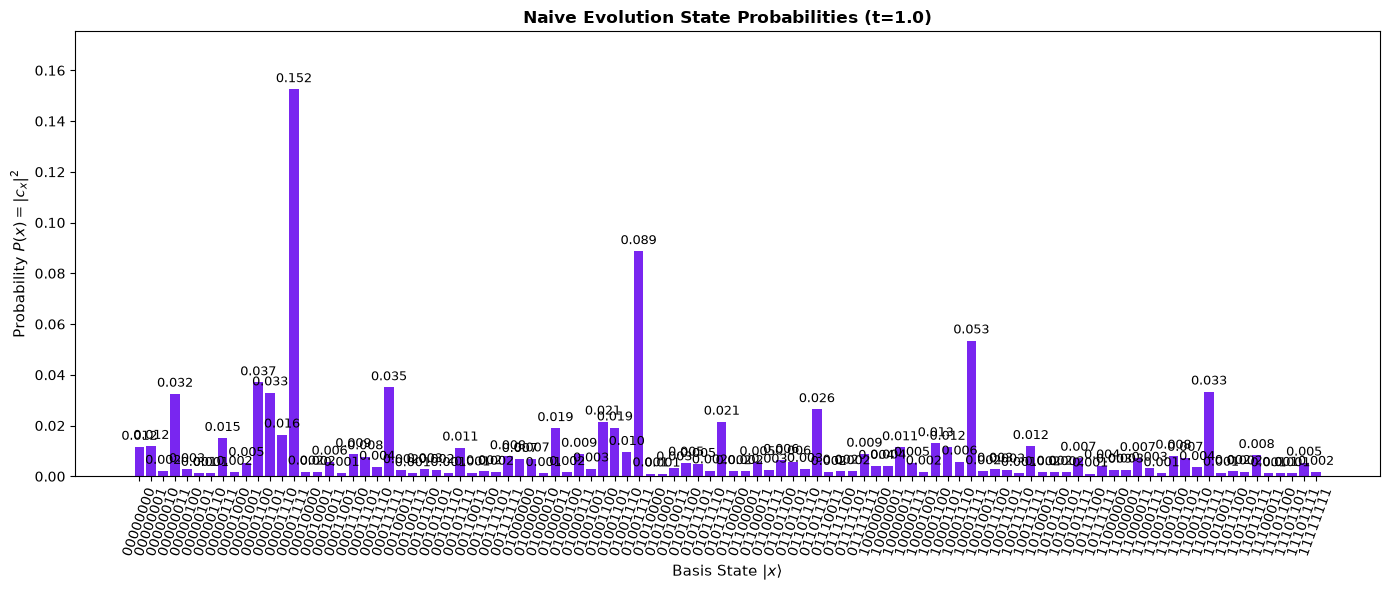

In [23]:
plot_state_histogram(evolved_state_naive, title="Naive Evolution State Probabilities (t=1.0)")

For this project the evolved state is the interesting part but to motivate why we want to avoid the "naive" appraoch and why the naive approach scales so badly even with a sparse hamiltonian as seen above, we can take a look at the Unitary $\hat{U}(t) = e^{-i \hat{H} t}$:

<Axes: title={'center': 'Unitary Sparsity Pattern\n(256x256 Matrix)'}, xlabel='Initial State Index ($j$)', ylabel='Final State Index ($i$)'>

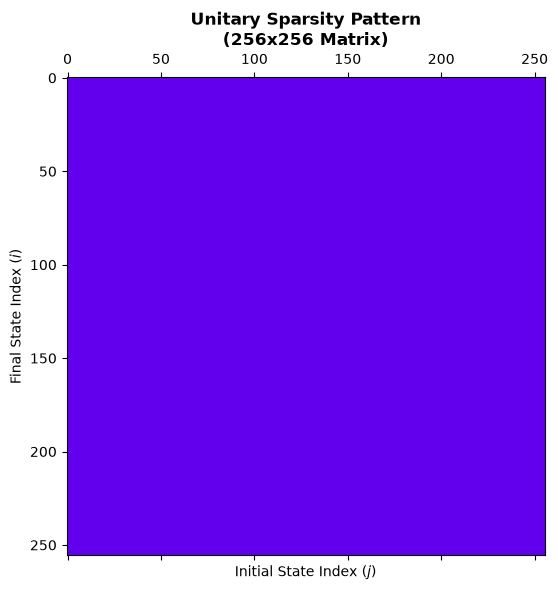

In [14]:
plot_operator_sparsity(unitary)

That is one dense matrix, to highlight this let's compare it to the Hamiltonian we started with:

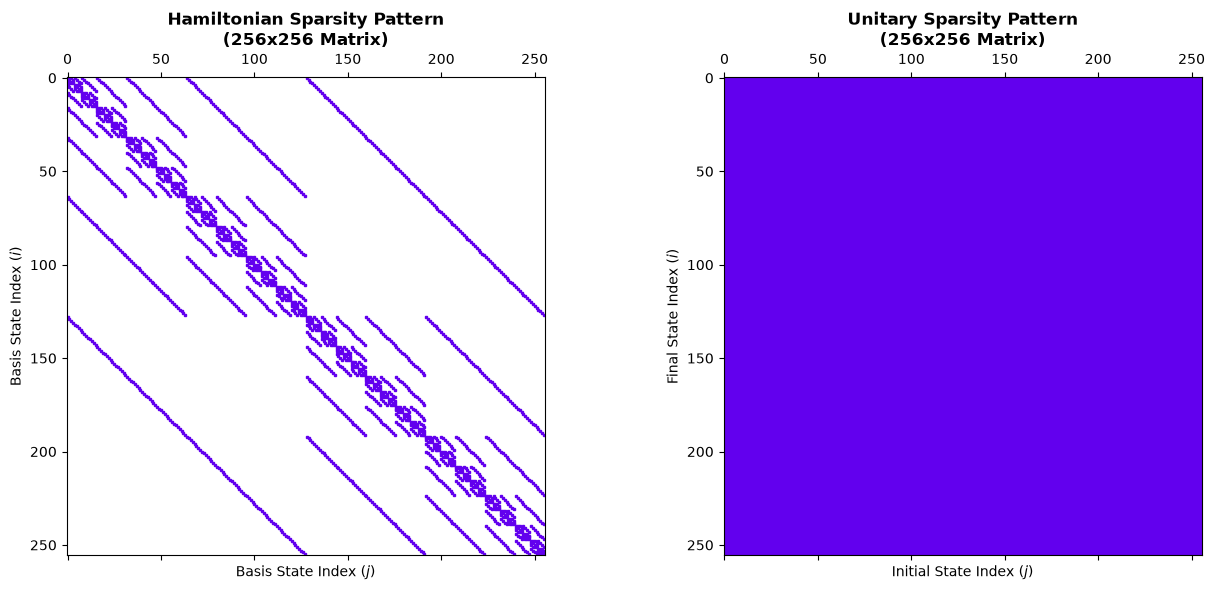

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

plot_operator_sparsity(np.array(hamiltonian), ax=ax1)
plot_operator_sparsity(unitary,  ax=ax2)

plt.show()

This really showcases what is often called the curse of diemensionality.

Comparing the sparsity patterns of the Hamiltonian $H$ and the time-evolution operator $U(t) = e^{-iHt}$ captures the core bottleneck of classical quantum simulation:

* **Sparse Hamiltonian ($H$):** Physical interactions are local, meaning $H$ contains only $\mathcal{O}(n \cdot 2^n)$ non-zero entries. It can easily be stored as a sparse matrix.
* **Dense Unitary ($U(t)$):** Matrix exponentiation floods the entire state space with non-zero phase and transition amplitudes through higher-order couplings ($H^k$). 

#### The Exponential Scaling Wall
1. **Memory Bottleneck $\mathcal{O}(4^n)$:** Storing the full dense unitary requires $(2^n)^2 = 4^n$ complex numbers. At 30 qubits, storing $U(t)$ alone would demand over **16 Exabytes of RAM**!
2. **Computational Bottleneck $\mathcal{O}(8^n)$:** Exact matrix exponentiation scales as $\mathcal{O}(D^3)$ where $D = 2^n$. Adding a single qubit increases the runtime by a factor of **8**.



<div class="alert alert-block alert-info">
<b>To be continued ... </b> 

This exponential explosion is precisely why we avoid building $U(t)$ explicitly. By projecting the evolution into a small Krylov subspace, we only ever compute sparse matrix-vector products $H|\psi\rangle$, completely bypassing the dense $4^n$ memory trap.

The other evolutions are introduced in the next (and shorter) <a href="tutorial_evolution_methods.ipynb"><b>tutorial_evolution_methods.ipynb</b></a>.
</div>